# HW2 Part 2: Single Stock Risk Report

A **parameterized** report for one stock: returns, rolling volatility, drawdown, Sharpe ratio, a 2x2 chart grid and a summary table.

- **Data:** the `ohlc_hw_cleaned` table created by `01_data_cleaning.ipynb` (run that notebook first).
- **Parameters:** the next cell is tagged `parameters`, so papermill (Part 3) can replace `ticker`, `start_date`, `end_date` and `db_path` when it runs this notebook for every stock.
- **Conventions:** returns, volatility, Sharpe and the daily statistics use daily **log returns** of the **adjusted close**. Values stay as fractions (0.05 = 5%) in all calculations and are only turned into percentages for display.

In [1]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Database with ohlc_hw_cleaned (relative to this notebook's folder)

In [2]:
# Parameters
ticker = "HD"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "C:\\Users\\sulib\\OneDrive\\Documentos\\ChatGPT\\MFE-Python-PreProgram\\UCB-MFE-python-preprogram-2026-winter\\Homeworks\\HW2\\Mauricio_Gutierrez\\data\\data.db"


The cell above carries the `parameters` tag in its metadata (JupyterLab: **Property Inspector → Cell Tags**).
The `# Parameters` comment alone is not enough: papermill looks for the tag, then inserts a new cell right after it with the values it was given.

## Setup

In [3]:
import sqlite3                       # read the cleaned table from the SQLite database
from contextlib import closing       # guarantees the database connection is closed afterwards
from pathlib import Path             # file paths that work on Windows, macOS and Linux

import matplotlib.dates as mdates    # readable date labels on the x-axis
import matplotlib.pyplot as plt      # charts
import numpy as np                   # log, exp, sqrt, NaN
import pandas as pd                  # tables and time series
import scrapbook as sb               # saves named results inside the executed notebook (collected in Part 3)
from IPython.display import display  # show DataFrames from inside functions or loops
from matplotlib.lines import Line2D  # legend entries for the colored price line

%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid")  # white background with light grid lines

# --- Report settings ---------------------------------------------------------
TRADING_DAYS = 252      # trading days per year: used to annualize daily numbers
VOL_WINDOW = 20         # rolling volatility window, in returns (20 returns need 21 prices)
MA_WINDOW = 50          # moving-average window, in prices
RISK_FREE_RATE = 0.02   # annual risk-free rate for the Sharpe ratio (course convention)

# One color scheme for every chart, so the same meaning always has the same color
COLORS = {
    "high_vol": "#d62728",   # red: above-average volatility
    "low_vol": "#2ca02c",    # green: average or below-average volatility
    "warm_up": "#9e9e9e",    # gray: rolling estimate not available yet
    "up": "#2ca02c",         # green: positive return
    "down": "#d62728",       # red: negative return
    "ma": "#1f3b73",         # navy: 50-day moving average
    "volatility": "#6a3d9a", # purple: rolling volatility line
    "drawdown": "#c0392b",   # dark red: drawdown
    "reference": "black",    # zero lines and mean lines
}

## 2.2 Data Loading

`load_clean_prices` checks the parameters before touching the data, so a bad value fails with a clear message
(Part 3 catches these errors and logs the ticker as failed). `check_history` then makes sure the period has enough
prices: one 20-day volatility estimate needs 20 returns, i.e. at least 21 prices.

In [4]:
def load_clean_prices(db_path: str, ticker: str, start_date: str, end_date: str) -> pd.DataFrame:
    """Load one ticker's cleaned daily prices between two dates (both included).

    Args:
        db_path: path to the SQLite database that contains `ohlc_hw_cleaned`.
        ticker: stock symbol, e.g. "AAPL".
        start_date, end_date: analysis period as "YYYY-MM-DD" strings.

    Returns:
        DataFrame indexed by date (sorted, oldest first) with open, high, low, close,
        adj_close and volume.

    Raises:
        FileNotFoundError: the database file does not exist.
        ValueError: a date is invalid, start_date is after end_date, the cleaned table is
            missing, or the ticker is not in the table.
    """
    database = Path(db_path).expanduser().resolve()
    if not database.is_file():
        raise FileNotFoundError(f"Database not found: {database}")

    # pd.Timestamp raises an error by itself if a date string is not a valid date
    start, end = pd.Timestamp(start_date), pd.Timestamp(end_date)
    if start > end:
        raise ValueError(f"start_date ({start_date}) must be on or before end_date ({end_date})")

    # "?mode=ro" opens the database read-only: the report can never change the data
    with closing(sqlite3.connect(database.as_uri() + "?mode=ro", uri=True)) as conn:
        tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type = 'table'", conn)["name"]
        if "ohlc_hw_cleaned" not in set(tables):
            raise ValueError("Table ohlc_hw_cleaned not found: run 01_data_cleaning.ipynb first")

        # The "?" placeholders let sqlite insert the values safely (never paste values into SQL text)
        known = pd.read_sql_query("SELECT 1 FROM ohlc_hw_cleaned WHERE ticker = ? LIMIT 1", conn, params=(ticker,))
        if known.empty:
            raise ValueError(f"Ticker {ticker!r} is not in ohlc_hw_cleaned")

        query = """
            SELECT ts, open, high, low, close, adj_close, volume
            FROM ohlc_hw_cleaned
            WHERE ticker = ? AND ts BETWEEN ? AND ?
            ORDER BY ts
        """
        # ts is stored as ISO text (YYYY-MM-DD), so BETWEEN compares dates correctly
        prices = pd.read_sql_query(
            query,
            conn,
            params=(ticker, start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d")),
            parse_dates=["ts"],   # turn the text dates into real datetimes
            index_col="ts",       # use the date as the row index (a time series)
        )
    return prices


def check_history(prices: pd.DataFrame, ticker: str, min_prices: int = VOL_WINDOW + 1) -> None:
    """Raise a clear ValueError if the loaded prices cannot support the report.

    Checks that there are at least `min_prices` rows (21 by default: 20 returns for one
    20-day volatility estimate), that each date appears once, and that every adjusted
    close is finite and positive (a log return needs positive prices).
    """
    if len(prices) < min_prices:
        raise ValueError(
            f"{ticker}: only {len(prices)} prices in the period; at least {min_prices} are needed "
            f"({VOL_WINDOW} returns for one {VOL_WINDOW}-day volatility estimate)"
        )
    if not prices.index.is_unique:
        raise ValueError(f"{ticker}: some dates appear more than once")
    adj = prices["adj_close"]
    if not (np.isfinite(adj) & (adj > 0)).all():
        raise ValueError(f"{ticker}: adj_close has missing, non-finite or nonpositive values")

In [5]:
prices = load_clean_prices(db_path, ticker, start_date, end_date)
check_history(prices, ticker)

# Requested period vs. the dates actually available: some tickers' data ends before end_date
first_date, last_date = prices.index.min(), prices.index.max()
print(f"{ticker} from {start_date} to {end_date}: {len(prices)} trading days")
print(f"Actual observations: {first_date:%Y-%m-%d} to {last_date:%Y-%m-%d}")

display(prices.head())
display(prices.tail())

HD from 2024-06-01 to 2024-11-30: 97 trading days
Actual observations: 2024-06-03 to 2024-10-18


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,333.65,333.65,326.84,328.01,326.03,3712800
2024-06-04,326.87,329.79,325.10,328.26,326.28,4296831
2024-06-05,328.50,330.46,325.92,330.26,328.27,2422400
2024-06-06,329.80,331.84,328.06,331.10,329.10,2979400
2024-06-07,325.73,328.82,323.93,327.03,325.06,2583813


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-10-14,411.48,416.42,411.30,415.42,415.42,2088700
2024-10-15,417.95,421.56,415.02,415.58,415.58,3693034
2024-10-16,413.87,418.74,413.87,418.61,418.61,2429037
2024-10-17,418.61,419.00,414.56,415.60,415.60,2013819
2024-10-18,416.65,416.66,413.24,415.00,415.00,2399976


## 2.3 Risk Metrics

The four functions the assignment asks for. Each one works on a pandas Series indexed by date.

- **`calculate_returns`**: daily log return `log(P_t / P_{t-1})`. Log returns add up over time: `exp(sum) - 1` is the total simple return.
- **`calculate_volatility`**: rolling sample standard deviation of log returns over 20 days, annualized with `sqrt(252)`.
- **`calculate_max_drawdown`**: despite its name (kept from the assignment), it returns the **per-date drawdown**, how far the price is below its highest level so far. It can recover. The **maximum** drawdown is the minimum of this Series.
- **`calculate_sharpe_ratio`**: the course formula `(mean * 252 - rf) / (std * sqrt(252))` with a 2% annual risk-free rate.

In [6]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns: log(P_t / P_(t-1)).

    The first value is NaN because the first day has no previous price.
    Prices must be sorted by date, finite and positive.
    """
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = VOL_WINDOW) -> pd.Series:
    """Calculate annualized rolling volatility.

    Rolling sample standard deviation (ddof=1) of daily log returns over `window` returns,
    multiplied by sqrt(252). The first `window` values stay NaN (the warm-up period: not
    enough returns yet); they are never filled with zero.
    """
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak.

    drawdown_t = (P_t - running_max_t) / running_max_t, which is 0 at a new high and
    negative below it. The maximum drawdown of the period is `drawdown.min()`.
    """
    running_peak = prices.cummax()   # highest price seen up to each date
    return (prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = RISK_FREE_RATE) -> float:
    """Calculate the annualized Sharpe ratio from daily log returns.

    Sharpe = (mean_daily_return * 252 - risk_free_rate) / (std_daily_return * sqrt(252)).
    Returns NaN when it is undefined: fewer than 2 returns, or zero/undefined volatility.
    """
    observed = returns.dropna()          # the first return is always NaN
    if len(observed) < 2:
        return np.nan
    std = observed.std()                 # sample standard deviation (ddof=1)
    if not np.isfinite(std) or np.isclose(std, 0):
        return np.nan
    return (observed.mean() * TRADING_DAYS - risk_free_rate) / (std * np.sqrt(TRADING_DAYS))

Quick checks on numbers small enough to verify by hand, so a mistake shows up before it reaches the report:

In [7]:
toy = pd.Series([100.0, 110.0, 99.0, 105.0])

# Log returns: log(110/100), log(99/110), log(105/99); the first is NaN
np.testing.assert_allclose(calculate_returns(toy).iloc[1:], np.log([1.10, 99 / 110, 105 / 99]))
# Log returns add up: exp(sum) - 1 equals the total simple return 105/100 - 1
assert np.isclose(np.expm1(calculate_returns(toy).sum()), 0.05)
# Drawdown: peaks are 100, 110, 110, 110 -> 0%, 0%, -10%, -4.55%
np.testing.assert_allclose(calculate_max_drawdown(toy), [0, 0, -0.10, 105 / 110 - 1])
# Volatility needs a full window: with window=2, the first two values are NaN
assert calculate_volatility(calculate_returns(toy), window=2).iloc[:2].isna().all()
# Sharpe is undefined when returns never vary
assert np.isnan(calculate_sharpe_ratio(pd.Series([0.01, 0.01, 0.01])))
print("All metric checks passed")

All metric checks passed


In [8]:
# Apply the functions to the report period. All price-based metrics use the ADJUSTED close,
# so dividends and splits do not show up as fake losses.
report = prices.copy()
report["log_return"] = calculate_returns(report["adj_close"])
report["volatility"] = calculate_volatility(report["log_return"])
report["ma_50"] = report["adj_close"].rolling(MA_WINDOW).mean()   # NaN until 50 prices exist
report["drawdown"] = calculate_max_drawdown(report["adj_close"])

sharpe_ratio = calculate_sharpe_ratio(report["log_return"])
max_drawdown = report["drawdown"].min()
mean_volatility = report["volatility"].mean()   # mean of the rolling estimates (NaN warm-up skipped)

print(f"Sharpe ratio:            {sharpe_ratio:.2f}")
print(f"Maximum drawdown:        {max_drawdown:.2%}")
print(f"Mean rolling volatility: {mean_volatility:.2%}")
if len(report) < MA_WINDOW:
    print(f"Note: the {MA_WINDOW}-day moving average is unavailable: only {len(report)} prices in the period.")

display(report[["adj_close", "log_return", "volatility", "ma_50", "drawdown"]].tail(10))

Sharpe ratio:            3.07
Maximum drawdown:        -7.93%
Mean rolling volatility: 20.46%


,adj_close,log_return,volatility,ma_50,drawdown
ts,,,,,
2024-10-07,408.06,-0.000735,0.130075,373.0624,-0.008552
2024-10-08,414.18,0.014886,0.130408,374.1562,0.000000
2024-10-09,416.07,0.004553,0.128177,375.2478,0.000000
2024-10-10,409.96,-0.014794,0.146033,376.1282,-0.014685
2024-10-11,411.90,0.004721,0.140988,377.2378,-0.010022
2024-10-14,415.42,0.008509,0.141829,378.4806,-0.001562
2024-10-15,415.58,0.000385,0.142442,379.8342,-0.001178
2024-10-16,418.61,0.007265,0.142663,381.1710,0.000000
2024-10-17,415.60,-0.007216,0.140806,382.6764,-0.007190


## 2.4 Visualization

A 2x2 grid of charts, 16x12 inches, built by `plot_risk_report`:

| Panel | Shows | How to read it |
|---|---|---|
| Top left | Adjusted close, colored by volatility, plus the 50-day moving average | Red where that day's 20-day volatility is above the report's mean, green at or below it, gray before the first estimate exists. The threshold uses the whole period, so the coloring is retrospective |
| Top right | Daily log returns as bars | Green up days, red down days |
| Bottom left | 20-day rolling volatility | Dashed line = mean; red shading above it, green below |
| Bottom right | Per-date drawdown | Deeper red = further below the previous peak; the dot marks the maximum drawdown |

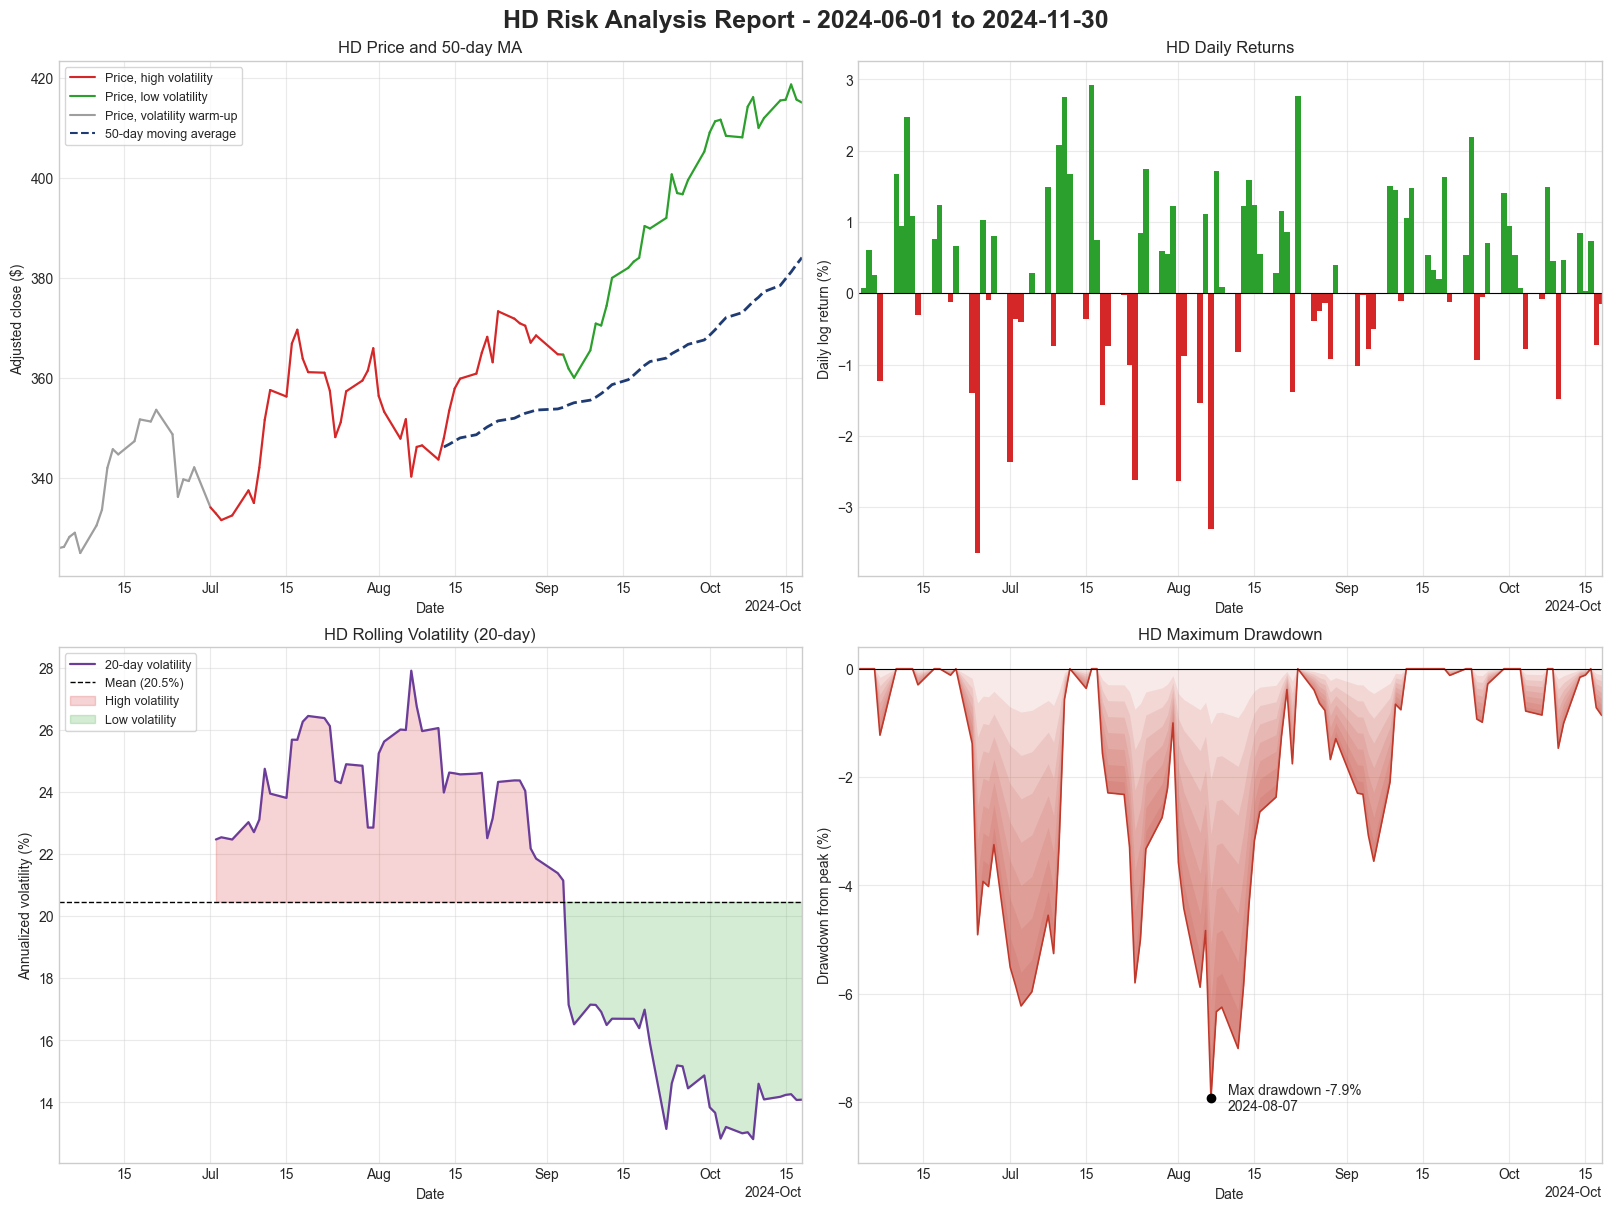

In [9]:
def format_date_axis(ax: plt.Axes) -> None:
    """Use compact, non-overlapping date labels on an x-axis."""
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))


def plot_price(ax: plt.Axes, df: pd.DataFrame, ticker: str) -> None:
    """Top left: adjusted close colored by volatility regime, plus the 50-day moving average."""
    threshold = df["volatility"].mean()
    # Draw the line one segment at a time (day i-1 to day i), colored by day i's volatility
    for i in range(1, len(df)):
        vol = df["volatility"].iloc[i]
        if pd.isna(vol):
            color = COLORS["warm_up"]           # no estimate yet
        elif vol > threshold:
            color = COLORS["high_vol"]
        else:
            color = COLORS["low_vol"]           # equal to the mean counts as low
        ax.plot(df.index[i - 1:i + 1], df["adj_close"].iloc[i - 1:i + 1], color=color, linewidth=1.6)

    ax.plot(df.index, df["ma_50"], color=COLORS["ma"], linewidth=2, linestyle="--")
    legend = [
        Line2D([], [], color=COLORS["high_vol"], label="Price, high volatility"),
        Line2D([], [], color=COLORS["low_vol"], label="Price, low volatility"),
        Line2D([], [], color=COLORS["warm_up"], label="Price, volatility warm-up"),
        Line2D([], [], color=COLORS["ma"], linestyle="--", label=f"{MA_WINDOW}-day moving average"),
    ]
    if df["ma_50"].isna().all():
        # Not enough prices for a single average: say so on the chart instead of hiding it
        ax.text(0.02, 0.04, f"{MA_WINDOW}-day MA unavailable: only {len(df)} prices",
                transform=ax.transAxes, fontsize=10, color=COLORS["ma"])
    ax.legend(handles=legend, loc="best", fontsize=9, frameon=True)   # "best" avoids covering the line
    ax.set(title=f"{ticker} Price and 50-day MA", xlabel="Date", ylabel="Adjusted close ($)")


def plot_returns(ax: plt.Axes, df: pd.DataFrame, ticker: str) -> None:
    """Top right: daily log returns as green (up) and red (down) bars, with a zero line."""
    returns_pct = df["log_return"] * 100                          # percent only for display
    colors = np.where(df["log_return"] >= 0, COLORS["up"], COLORS["down"])
    ax.bar(df.index, returns_pct, width=1.0, color=colors)
    ax.axhline(0, color=COLORS["reference"], linewidth=0.8)
    ax.set(title=f"{ticker} Daily Returns", xlabel="Date", ylabel="Daily log return (%)")


def plot_volatility(ax: plt.Axes, df: pd.DataFrame, ticker: str) -> None:
    """Bottom left: 20-day rolling volatility with its mean, shading high and low regimes."""
    vol_pct = df["volatility"] * 100
    mean_pct = df["volatility"].mean() * 100
    ax.plot(df.index, vol_pct, color=COLORS["volatility"], linewidth=1.6, label=f"{VOL_WINDOW}-day volatility")
    ax.axhline(mean_pct, color=COLORS["reference"], linestyle="--", linewidth=1, label=f"Mean ({mean_pct:.1f}%)")
    # interpolate=True makes the shading meet exactly where the line crosses the mean
    ax.fill_between(df.index, vol_pct, mean_pct, where=vol_pct > mean_pct,
                    color=COLORS["high_vol"], alpha=0.2, interpolate=True, label="High volatility")
    ax.fill_between(df.index, vol_pct, mean_pct, where=vol_pct <= mean_pct,
                    color=COLORS["low_vol"], alpha=0.2, interpolate=True, label="Low volatility")
    ax.legend(loc="upper left", fontsize=9, frameon=True)
    ax.set(title=f"{ticker} Rolling Volatility ({VOL_WINDOW}-day)", xlabel="Date",
           ylabel="Annualized volatility (%)")


def plot_drawdown(ax: plt.Axes, df: pd.DataFrame, ticker: str) -> None:
    """Bottom right: drawdown area with a red gradient, marking the maximum drawdown."""
    dd_pct = df["drawdown"] * 100
    # Gradient: several transparent fills stacked on top of each other. Each covers the area from the
    # drawdown line up to a fraction of it, so the deepest part is covered most often and looks darkest.
    for fraction in np.linspace(0, 0.9, 8):
        ax.fill_between(df.index, dd_pct, dd_pct * fraction, color=COLORS["drawdown"], alpha=0.10, linewidth=0)
    ax.plot(df.index, dd_pct, color=COLORS["drawdown"], linewidth=1.2)
    ax.axhline(0, color=COLORS["reference"], linewidth=0.8)

    worst_date = df["drawdown"].idxmin()           # date of the maximum drawdown
    worst_value = dd_pct.loc[worst_date]
    ax.scatter([worst_date], [worst_value], color="black", zorder=5)
    ax.annotate(f"Max drawdown {worst_value:.1f}%\n{worst_date:%Y-%m-%d}",
                xy=(worst_date, worst_value), xytext=(12, 0), textcoords="offset points",
                fontsize=10, va="center")
    ax.set_ylim(bottom=min(worst_value * 1.15, -1))   # leave room below the deepest point
    ax.set(title=f"{ticker} Maximum Drawdown", xlabel="Date", ylabel="Drawdown from peak (%)")


def plot_risk_report(df: pd.DataFrame, ticker: str, start_date: str, end_date: str) -> plt.Figure:
    """Build the 2x2 risk report figure (16x12 inches) and return it."""
    fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout="constrained")
    plot_price(axes[0, 0], df, ticker)
    plot_returns(axes[0, 1], df, ticker)
    plot_volatility(axes[1, 0], df, ticker)
    plot_drawdown(axes[1, 1], df, ticker)
    for ax in axes.flat:                 # same finishing touches on every panel
        ax.grid(True, alpha=0.4)
        format_date_axis(ax)
        ax.set_xlim(df.index.min(), df.index.max())   # same date range everywhere, easy to compare panels
    fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=18, fontweight="bold")
    return fig


fig = plot_risk_report(report, ticker, start_date, end_date)
plt.show()

## 2.5 Summary Statistics

Formulas (from the assignment), with `n` = number of nonmissing daily log returns:

| Metric | Formula |
|---|---|
| Total Return | `last_adj_close / first_adj_close - 1` |
| Annualized Return | `exp(sum(log_returns) * 252 / n) - 1` (compounded) |
| Annualized Volatility | `std(log_returns) * sqrt(252)` over the whole period (not the mean rolling volatility) |
| Sharpe Ratio | `calculate_sharpe_ratio(log_returns)` |
| Maximum Drawdown | `min(drawdown)` |
| Best / Worst Day | largest / smallest daily log return |
| Positive Days | positive returns / **all** nonmissing returns (zero days count in the denominator) |
| Average Up / Down Day | mean of the positive / negative log returns, `N/A` if there are none |

In [10]:
def summarize_performance(df: pd.DataFrame) -> dict[str, float]:
    """Calculate the summary metrics as raw fractions (0.05 = 5%); NaN where undefined.

    Needs the columns adj_close, log_return and drawdown.
    """
    returns = df["log_return"].dropna()     # drop the first day's missing return
    n = len(returns)
    up, down = returns[returns > 0], returns[returns < 0]
    adj = df["adj_close"]
    return {
        "Total Return": adj.iloc[-1] / adj.iloc[0] - 1,
        "Annualized Return": np.expm1(returns.sum() * TRADING_DAYS / n) if n else np.nan,
        "Annualized Volatility": returns.std() * np.sqrt(TRADING_DAYS),
        "Sharpe Ratio": calculate_sharpe_ratio(returns),
        "Maximum Drawdown": df["drawdown"].min(),
        "Best Day": returns.max(),
        "Worst Day": returns.min(),
        "Positive Days": len(up) / n if n else np.nan,
        "Average Up Day": up.mean() if len(up) else np.nan,
        "Average Down Day": down.mean() if len(down) else np.nan,
    }


def format_metric(name: str, value: float) -> str:
    """Format one metric for display: N/A, a plain number, or a percentage."""
    if pd.isna(value):
        return "N/A"
    if name == "Sharpe Ratio":
        return f"{value:.2f}"            # a ratio, not a percentage
    if name == "Annualized Volatility":
        return f"{value:.2%}"            # always >= 0, so no sign
    if name == "Positive Days":
        return f"{value:.1%}"
    return f"{value:+.2%}"               # returns and drawdowns: show the + or - sign


def print_summary_table(metrics: dict[str, float]) -> None:
    """Print the metrics as the two-column table shown in the assignment."""
    print(f"{'Metric':<24}  {'Value':>8}")
    print(f"{'-' * 24}  {'-' * 8}")
    for name, value in metrics.items():
        print(f"{name:<24}  {format_metric(name, value):>8}")


summary = summarize_performance(report)
print(f"{ticker}: {first_date:%Y-%m-%d} to {last_date:%Y-%m-%d} ({len(report)} trading days)\n")
print_summary_table(summary)

HD: 2024-06-03 to 2024-10-18 (97 trading days)

Metric                       Value
------------------------  --------
Total Return               +27.29%
Annualized Return          +88.40%
Annualized Volatility       19.97%
Sharpe Ratio                  3.07
Maximum Drawdown            -7.93%
Best Day                    +2.93%
Worst Day                   -3.64%
Positive Days                59.4%
Average Up Day              +1.05%
Average Down Day            -0.92%


## Results for Part 3

`sb.glue(name, value)` stores a named value inside the executed copy of this notebook. When `03_run_all_stocks.py` runs this notebook for every ticker, it reads these values back instead of recalculating them.
All values are fractions; `avg_volatility` is the **mean of the rolling volatility**, which is different from the whole-period annualized volatility above.

In [11]:
# float(...) turns numpy numbers into plain Python floats, which scrapbook stores as JSON
sb.glue("ticker", ticker)
sb.glue("start_date", start_date)                       # requested period
sb.glue("end_date", end_date)
sb.glue("first_date", f"{first_date:%Y-%m-%d}")         # actual coverage of the data
sb.glue("last_date", f"{last_date:%Y-%m-%d}")
sb.glue("trading_days", int(len(report)))
sb.glue("avg_daily_return", float(report["log_return"].mean()))   # mean daily log return
sb.glue("avg_volatility", float(mean_volatility))                 # mean of the rolling volatility
sb.glue("max_drawdown", float(max_drawdown))                      # worst drawdown in the period
sb.glue("sharpe_ratio", float(sharpe_ratio))                      # NaN if undefined
sb.glue("total_return", float(summary["Total Return"]))           # last / first adjusted close - 1
print("Results saved with scrapbook for the Part 3 summary.")

Results saved with scrapbook for the Part 3 summary.
